# 과제1 신경망 학습 재현

63회차의전처리특징과공개초기가중치에서본체학습을재현하는절차다. 제출가중치는 `model/round63.ckpt`로고정돼있다. 재학습출력은별도폴더에저장한다.


In [1]:
from pathlib import Path
import os, sys, json, subprocess
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'model' / 'round63.ckpt').exists())
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'src' / 'vendor')]
import numpy as np
import pandas as pd
print('Round63 | 과제1 | 고정 모델 실행')

Round63 | 과제1 | 고정 모델 실행


## FIT 기반 특징과 관측일 크롭

입력은63회차에서FIT만으로학습한형상·해역기저를적용한476열과실제관측일크롭이다.337개요약·배치·상태에65개관계와74개실제인접시간특징을추가했다. 이노트북의재학습명령은해당고정특징에서시작하며,원자료의기저적합을다시수행하지않는다.


In [2]:
split = pd.read_csv(ROOT/'data/reproduction/fixed_split.csv', index_col='id')
prepared = np.load(ROOT/'data/reproduction/training_inputs.npz')
print(split['split'].value_counts().to_dict())
print({'FIT': prepared['raw_train'].shape, '크롭': prepared['raw_crop'].shape, '쿼리': prepared['raw_query_full'].shape})
assert prepared['raw_train'].shape == (4423,476)
assert not set(split.index[split.split=='FIT']) & set(split.index[split.split=='REPORT'])

{'FIT': 4423, 'REPORT': 1475, 'TUNE': 1474}
{'FIT': (4423, 476), '크롭': (4423, 476), '쿼리': (2949, 476)}


## 부분 구조와 학습 파라미터

원본ICL블록4~7의attention·FFN·norm과블록8~11의FFN게이트만학습한다. `W2(GELU(W1x) * 2*sigmoid(Gx))` 구조에서게이트를0으로초기화한다. 원본초기함수를보존한상태로학습을시작한다.


In [3]:
import torch
checkpoint = torch.load(ROOT/'model/round63.ckpt', map_location='cpu', weights_only=False)
middle = tuple(f'icl_predictor.tf_icl.blocks.{i}.' for i in range(4,8))
gates = tuple(f'icl_predictor.tf_icl.blocks.{i}.ffn_gate.' for i in range(8,12))
old_count = sum(v.numel() for k,v in checkpoint['state_dict'].items() if k.startswith(middle))
gate_count = sum(v.numel() for k,v in checkpoint['state_dict'].items() if k.startswith(gates))
print({'원본중간4블록': old_count, '뒤4게이트': gate_count, '합계': old_count+gate_count})
assert (old_count,gate_count) == (8578048,2101248)
del checkpoint

{'원본중간4블록': 8578048, '뒤4게이트': 2101248, '합계': 10679296}


## 학습 손실과 선택

FIT2-fold의공통쿼리를20개과제에사용한다.4개native앙상블의순열을정렬한뒤결합CE·공개교사T2 KL·JS를계산한다. 관계비중0.5는학습전에고정했다. 두번의동일순전파로cotangent를구해본체경사를누적하며,BF16weightcache는끄고GradScaler는사용하지않는다. gradient clip은1.0이다.

최대6epoch·epoch당2update,학습률원본1e-5·게이트1e-4,patience1이다. TUNE에서양의본체반영비중과체크포인트를선택하며epoch0은제외한다. 실제선택은epoch1·update2였고총4update후종료됐다.


In [4]:
print({'공개초기화': 'model/public_init.ckpt', '학습과제': 20, '앙상블': 4, 'FIT폴드': 2, '최대epoch': 6, '선택기준': 'TUNE micro-F1 then macro-F1', '반영격자': [0,.1,.25,.5,.75,1], 'grad_clip': 1.0})

{'공개초기화': 'model/public_init.ckpt', '학습과제': 20, '앙상블': 4, 'FIT폴드': 2, '최대epoch': 6, '선택기준': 'TUNE micro-F1 then macro-F1', '반영격자': [0, 0.1, 0.25, 0.5, 0.75, 1], 'grad_clip': 1.0}


## 선택적 재학습 실행

기본값은False다. 실행하면공개기준20과제와고정표현160개를새로만들고원래학습구현을호출한다. 출력폴더는기존폴더와겹치면중단한다. 제출체크포인트와전역실험상태는바꾸지않는다.


In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT/'scripts/train.py'), '--output', str(ROOT/'runs/round63_replay')], check=True)
else:
    print({'제출체크포인트': 'round63.ckpt', '선택epoch': 1, '선택update': 2, '실제update': 4})

{'제출체크포인트': 'round63.ckpt', '선택epoch': 1, '선택update': 2, '실제update': 4}


## 평가 기록

배포의relation비중은0이므로최종추론은14과제다. 제출용코드로기존2,949척의클래스를재현했다. REPORT는반복개발검토에사용한구간이다.


{'passed': True, 'all_query_boats': 2949, 'changed_predictions': 0, 'REPORT_micro_f1': 0.6122033898305085, 'TUNE_micro_f1': 0.601763907734057, 'normalized_probability_sums': True, 'deployed_tasks': 14, 'training_performed': False, 'maximum_log_score_difference': 6.887263275245914e-07}


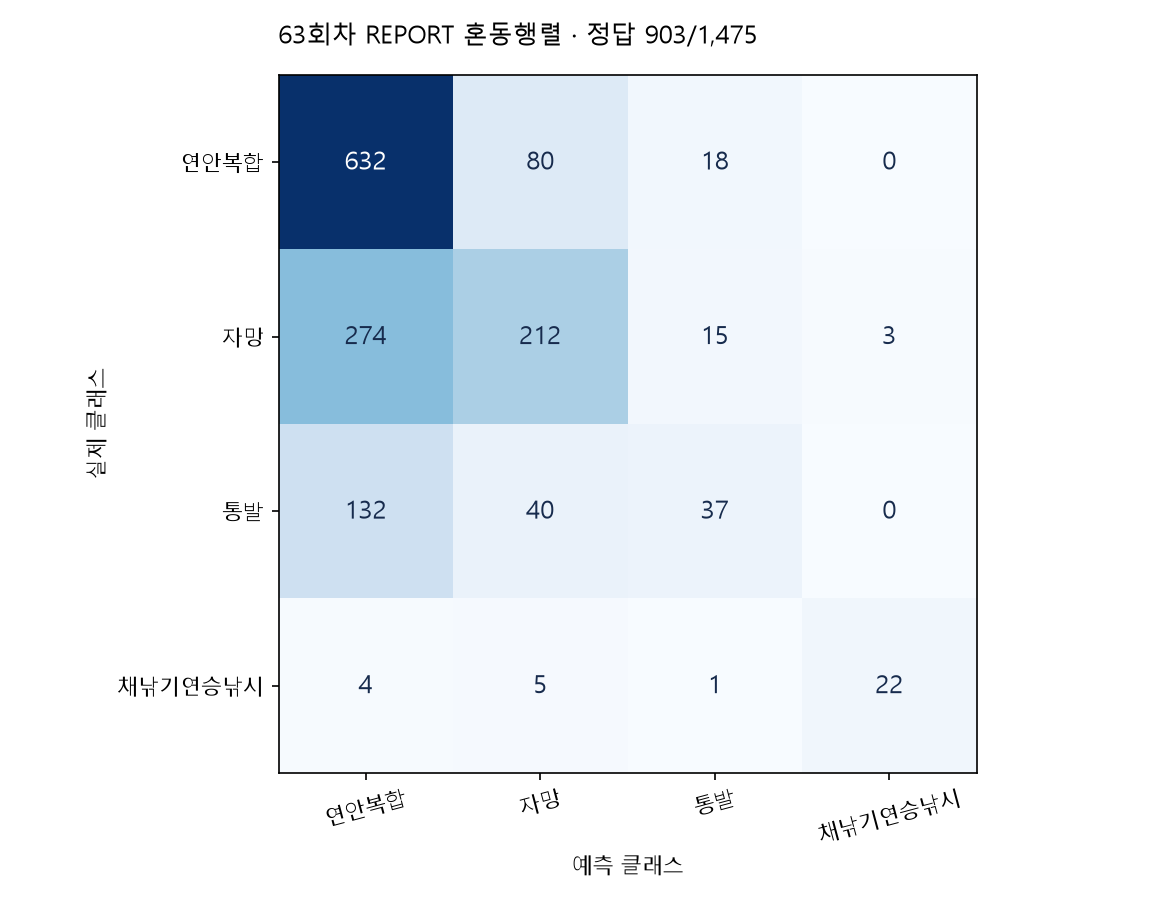

In [6]:
record = json.loads((ROOT/'validation/report_regression.json').read_text(encoding='utf-8'))
print(record)
assert record['passed']
from IPython.display import Image, display
display(Image(filename=str(ROOT/'figures/report_confusion.png')))